<a href="https://colab.research.google.com/github/KinzaaSheikh/-Mars_terrain_classifier_on_NASA_JPL-s_HiRISE_v3.2_dataset/blob/main/Mars_terrain_classifier_on_NASA_JPL's_HiRISE_v3_2_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Dependencies and Download Dataset

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
# Download once, unzip on every session

import os
DRIVE_DIR = '/content/drive/MyDrive/datasets/hirise'
os.makedirs(DRIVE_DIR, exist_ok=True)
ZIP = f'{DRIVE_DIR}/hirise-map-proj-v3_2.zip'

if not os.path.exists(ZIP):   # skips the download next time
    !wget -O "{ZIP}" "https://zenodo.org/records/4002935/files/hirise-map-proj-v3_2.zip?download=1"

!unzip -q -o "{ZIP}" -d /content/hirise
!ls /content/hirise

hirise-map-proj-v3_2  __MACOSX


In [15]:
# Load the labels and official splits

import glob, re
import pandas as pd
from PIL import Image

In [16]:
ROOT = '/content/hirise'
label_file    = glob.glob(f'{ROOT}/**/*train_val_test.txt', recursive=True)[0]
classmap_file = glob.glob(f'{ROOT}/**/*classmap.csv', recursive=True)[0]
IMG_DIR       = glob.glob(f'{ROOT}/**/map-proj-v3_2', recursive=True)[0]

In [17]:
df = pd.read_csv(label_file, sep=r'\s+', header=None,
                 names=['filename', 'class_id', 'split'])
cm = pd.read_csv(classmap_file, header=None, names=['class_id', 'name'])
cm = cm[pd.to_numeric(cm['class_id'], errors='coerce').notna()]
CLASS_NAMES = dict(zip(cm['class_id'].astype(int), cm['name']))

In [18]:
print(CLASS_NAMES)
print(df['split'].value_counts())
print('rows:', len(df), '| unique files:', df['filename'].nunique())

{0: 'other', 1: 'crater', 2: 'dark dune', 3: 'slope streak', 4: 'bright dune', 5: 'impact ejecta', 6: 'swiss cheese', 7: 'spider'}
split
train    51058
val      14959
test      1793
Name: count, dtype: int64
rows: 67810 | unique files: 64947


In [19]:
# Check that no landmark is in more than one split

AUG = re.compile(r'-(r90|r180|r270|fh|fv|brt)$')
df['landmark'] = df['filename'].map(lambda f: AUG.sub('', os.path.splitext(f)[0]))
df['source']   = df['filename'].map(lambda f: '_'.join(f.split('_')[:3]))  # parent HiRISE image

print(df['filename'].sample(8, random_state=0).tolist())   # eyeball the suffixes
print('unique landmarks:', df['landmark'].nunique(), '(expect ~10,815)')

for col in ['landmark', 'source']:
    leaked = df.groupby(col)['split'].nunique().loc[lambda s: s > 1]
    print(f'{col}s appearing in >1 split: {len(leaked)}')

['ESP_017395_1700_RED-0077-r270.jpg', 'ESP_036804_2345_RED-0345-r180.jpg', 'ESP_036987_1825_RED-0033-fv.jpg', 'ESP_020606_1445_RED-0241-brt.jpg', 'ESP_028733_1370_RED-0583-r90.jpg', 'PSP_006879_2335_RED-0437-brt.jpg', 'ESP_013281_1930_RED-0087-fh.jpg', 'ESP_034590_1795_RED-0251-r180.jpg']
unique landmarks: 10815 (expect ~10,815)
landmarks appearing in >1 split: 0
sources appearing in >1 split: 0


In [20]:
# test set is locked away

df[df.split == 'test'].to_csv(f'{DRIVE_DIR}/test_LOCKED.csv', index=False)
dev_df = df[df.split != 'test'].copy()   # use only this until Friday

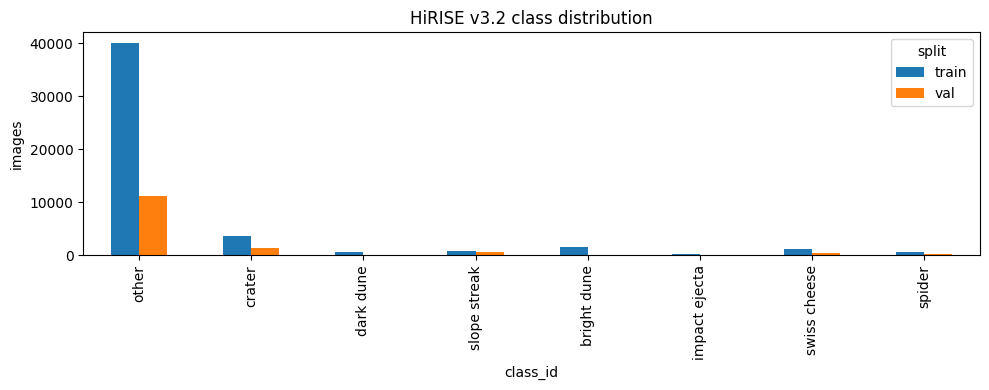

In [21]:
# class distribution (train & val)

counts = (dev_df.drop_duplicates('filename')
          .groupby(['class_id', 'split']).size().unstack(fill_value=0))
counts.index = counts.index.map(CLASS_NAMES)
counts.plot(kind='bar', figsize=(10, 4))
plt.ylabel('images'); plt.title('HiRISE v3.2 class distribution'); plt.tight_layout(); plt.show()

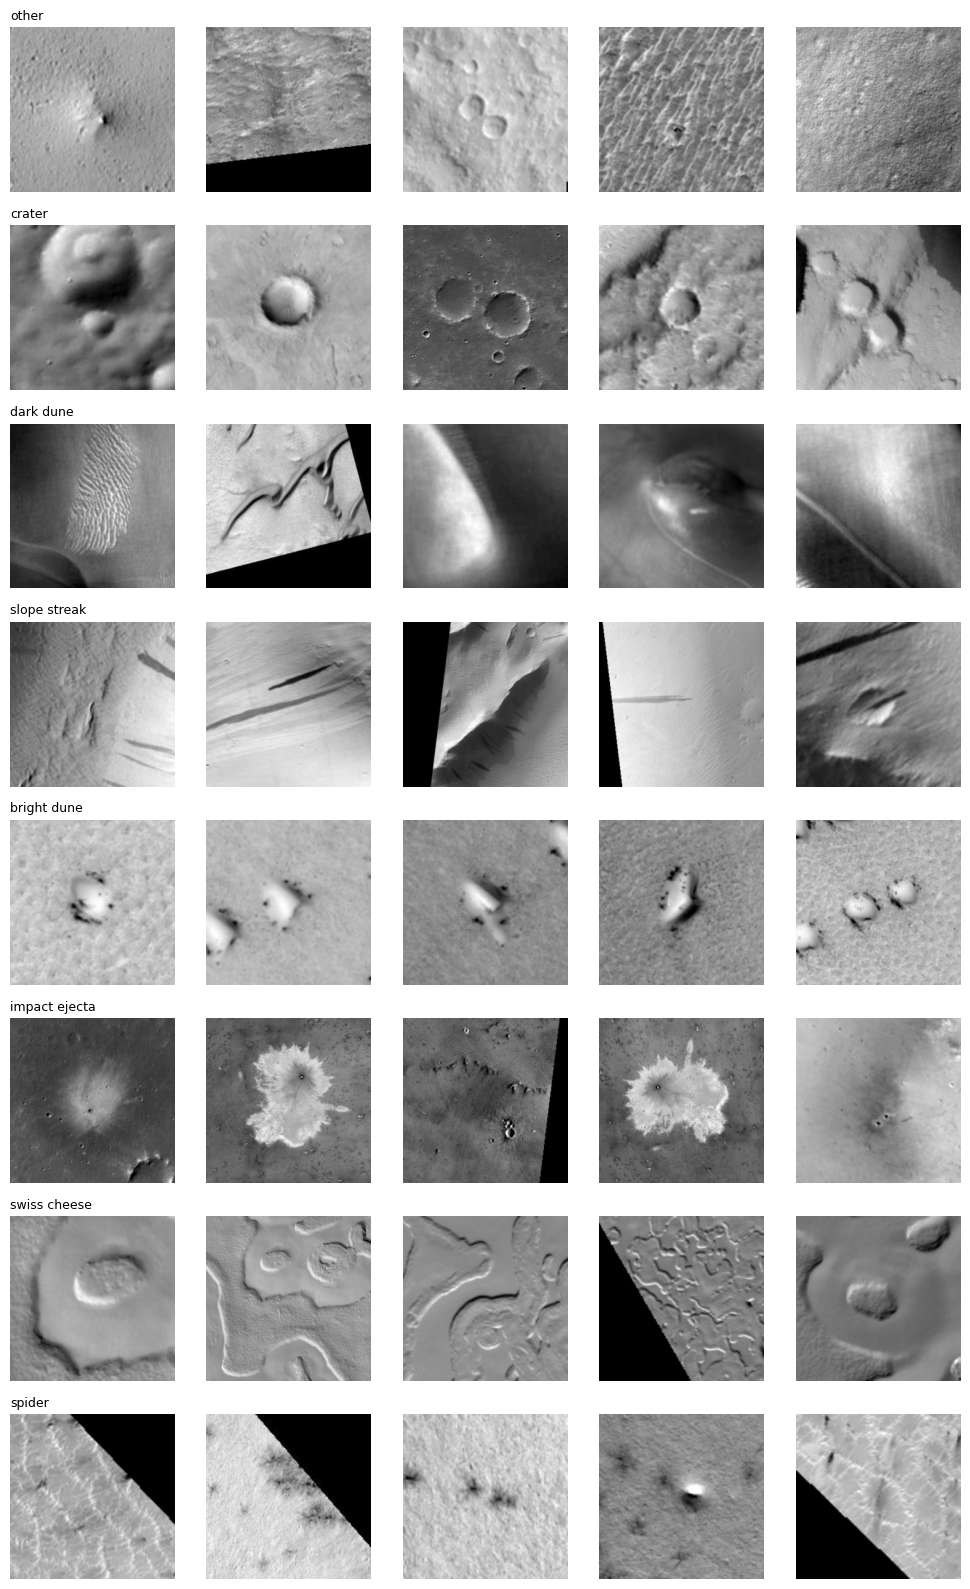

In [23]:
# Fix IMG_DIR to exclude __MACOSX folder if necessary, then sample images from each class
import os

# Correcting IMG_DIR manually if it incorrectly references __MACOSX
if "__MACOSX" in IMG_DIR:
    IMG_DIR = glob.glob(f'{ROOT}/**/map-proj-v3_2', recursive=True)
    # Filter out paths containing __MACOSX
    IMG_DIR = [path for path in IMG_DIR if "__MACOSX" not in path][0]

train = dev_df[dev_df.split == 'train'].drop_duplicates('filename')
k = 5
fig, axes = plt.subplots(len(CLASS_NAMES), k, figsize=(2*k, 2*len(CLASS_NAMES)))
for r, (cid, name) in enumerate(CLASS_NAMES.items()):
    picks = train[train.class_id == cid]
    picks = picks.sample(min(k, len(picks)), random_state=0)
    for c in range(k):
        ax = axes[r, c]; ax.axis('off')
        if c < len(picks):
            img_path = os.path.join(IMG_DIR, picks.iloc[c].filename)
            if os.path.exists(img_path):
                ax.imshow(Image.open(img_path), cmap='gray')
            else:
                print(f"Warning: File not found {img_path}")
    axes[r, 0].set_title(name, loc='left', fontsize=9)
plt.tight_layout(); plt.show()